# Exercice 6 - Apprentissage supervisé : reconnaître l'espèce d'un animal sur photo

## Le jeu de données :

Je travaille sur un sous-ensemble équilibré du jeu de données Animals-10, qui rassemble des photographies d'animaux collectées sur le web, réparties en dix espèces désignées ici par leurs noms français : araignée, chat, cheval, chien, écureuil, éléphant, mouton, papillon, poule et vache. J'ai retenu exactement 1 000 images par espèce, soit 10 000 images au total, par échantillonnage aléatoire à graine fixée (script scripts/reduce_animals10.py).

Ces images sont très hétérogènes : les tailles s'étalent de 60x57 pixels pour la plus petite jusqu'à 6720 px de largeur et 5365 px de hauteur au plus, ces deux maxima étant atteints sur des images distinctes, avec des cadrages, éclairages, arrière-plans et poses variés, et des formats mélangés (jpeg, jpg, png, dont 24 images en RGBA converties en RGB au chargement). La classe chien regroupe par exemple de nombreuses races d'apparences très différentes. Cette variance intra-classe est la difficulté centrale du problème. Le jeu n'est pas pré-découpé, je fais moi-même la séparation train/test.

URL du jeu de données : https://www.kaggle.com/datasets/alessiocorrado99/animals10

## L'objectif : ce que je prédis, à partir de quoi

Je prédis l'espèce de l'animal présent sur l'image, un problème de classification à 10 classes, à partir de descripteurs visuels classiques et sans réseau de neurones. Savoir faire cela automatiquement a une utilité directe, par exemple pour trier les millions de clichés des pièges photographiques utilisés en écologie, ou pour indexer une photothèque.

Chaque image est convertie en RGB, redimensionnée en 64x64, puis résumée par deux familles de caractéristiques concaténées :

- un histogramme de couleur RGB (16 intervalles par canal, 48 dimensions), qui capte la palette dominante de l'image, par exemple le vert d'une prairie ou le brun d'un pelage,
- un descripteur HOG calculé sur la version en niveaux de gris (histogrammes d'orientations des gradients locaux, 1 764 dimensions), qui capte la forme générale et les contours.

L'espèce est donc prédite comme fonction de ces 1 812 descripteurs. L'extraction sur 10 000 images étant coûteuse, les caractéristiques sont mises en cache dans data/animals10_features et rechargées aux exécutions suivantes.

In [1]:
%matplotlib inline
# Extraction des caractéristiques : chaque image devient un vecteur de 1812
# dimensions (histogramme couleur + HOG). Le cache évite de refaire ce travail.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.color import rgb2gray
from skimage.feature import hog

DATA_DIR = Path.cwd().parent / "data" / "animals10_1k"
CACHE_DIR = Path.cwd().parent / "data" / "animals10_features"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42


def image_en_vecteur(chemin):
    """
    Convertit une image en un vecteur de caractéristiques visuelles.

    Paramètres :
        chemin (Path) : fichier image à charger.

    Retour :
        np.ndarray : concaténation de l'histogramme couleur (48) et du HOG (1764).
    """
    with Image.open(chemin) as im:
        rgb = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32) / 255.0
    parties = []
    for canal in range(3):
        h, _ = np.histogram(rgb[:, :, canal], bins=16, range=(0.0, 1.0))
        parties.append(h.astype(np.float32))
    couleur = np.concatenate(parties)
    couleur /= couleur.sum()
    contours = hog(rgb2gray(rgb), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True).astype(np.float32)
    return np.concatenate([couleur, contours])


def charger_ou_extraire():
    """
    Charge les caractéristiques depuis le cache, ou les extrait puis les met en cache.

    Retour :
        tuple : matrice X (n, 1812), étiquettes y (n,), liste des noms de classes.
    """
    x_cache, y_cache, c_cache = CACHE_DIR / "X_classic.npy", CACHE_DIR / "y.npy", CACHE_DIR / "classes.json"
    classes = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
    if x_cache.exists() and y_cache.exists():
        print("caractéristiques rechargées depuis le cache")
        return np.load(x_cache), np.load(y_cache), classes
    X, y = [], []
    for etiquette, nom in enumerate(classes):
        fichiers = sorted(f for f in (DATA_DIR / nom).iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
        for f in fichiers:
            X.append(image_en_vecteur(f))
            y.append(etiquette)
        print(f"  {nom} : {len(fichiers)} images traitées")
    X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.int64)
    np.save(x_cache, X)
    np.save(y_cache, y)
    c_cache.write_text(json.dumps({"classes": classes}, indent=2))
    return X, y, classes


X, y, classes = charger_ou_extraire()
print(f"matrice de caractéristiques : {X.shape}, {len(classes)} classes équilibrées {np.bincount(y)}")

caractéristiques rechargées depuis le cache
matrice de caractéristiques : (10000, 1812), 10 classes équilibrées [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [2]:
# vérification des affirmations sur les images brutes : plage de tailles et modes
from collections import Counter

tailles, modes = [], Counter()
for nom in classes:
    for f in (DATA_DIR / nom).iterdir():
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            with Image.open(f) as im:
                tailles.append(im.size)
                modes[im.mode] += 1
largeurs = [w for w, h in tailles]
hauteurs = [h for w, h in tailles]
print(f"tailles : de {min(largeurs)}x{min(hauteurs)} à {max(largeurs)}x{max(hauteurs)} pixels")
print(f"modes des images : {dict(modes)}")

tailles : de 60x57 à 6720x5365 pixels
modes des images : {'RGB': 9976, 'RGBA': 24}


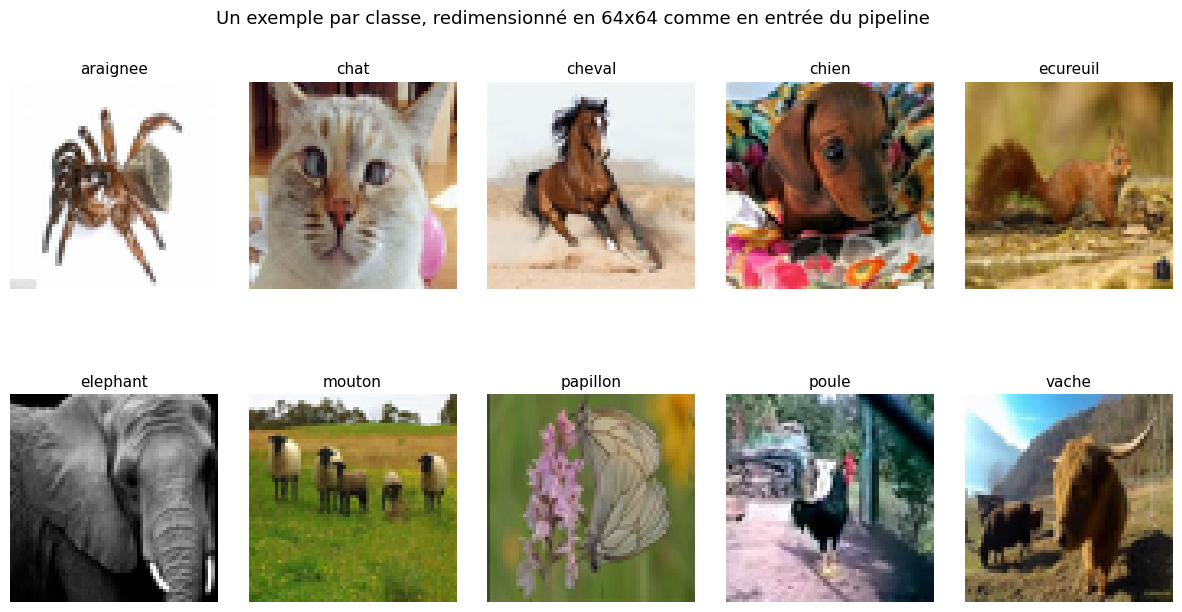

In [3]:
# un exemple d'image par classe, pour se représenter la difficulté du problème
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, nom in zip(axes.ravel(), classes):
    fichiers = sorted(f for f in (DATA_DIR / nom).iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
    with Image.open(fichiers[0]) as im:
        ax.imshow(im.convert("RGB").resize((64, 64)))
    ax.set_title(nom, fontsize=11)
    ax.axis("off")
fig.suptitle("Un exemple par classe, redimensionné en 64x64 comme en entrée du pipeline", fontsize=13)
fig.subplots_adjust(hspace=0.3, wspace=0.15, top=0.9)
plt.show()

## Protocole :

Séparation stratifiée train/test à 80/20 avec graine fixée, soit 8 000 images d'entraînement et 2 000 de test. Les caractéristiques vivent sur des échelles différentes (histogramme normalisé contre amplitudes HOG), donc chaque modèle est placé dans un Pipeline avec StandardScaler en tête, ré-ajusté sur chaque pli d'entraînement de la validation croisée pour exclure toute fuite.

Je compare trois classifieurs, chacun réglé par GridSearchCV en validation croisée stratifiée à 5 plis sur le train uniquement : une régression logistique (référence linéaire, réglage de C), un SVC à noyau RBF (réglage de C et gamma) et une forêt aléatoire (réglage du nombre d'arbres et de la profondeur). Le champion est sélectionné sur l'accuracy de validation croisée, le test n'étant évalué qu'à titre de rapport final. Côté solveurs, rien à régler de particulier : lbfgs pour la logistique (max_iter relevé), libsvm pour le SVC, et les arbres ne demandent pas de standardisation mais la subissent sans dommage.

In [4]:
# entraînement et réglage des trois modèles, sélection du champion par CV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"train : {X_train.shape}, test : {X_test.shape}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
modeles = {
    "LogisticRegression": (Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))]), {"clf__C": [0.01, 0.1, 1, 10]}),
    "SVC_rbf": (Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf"))]), {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01]}),
    "RandomForest": (Pipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]), {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 20]}),
}

resultats = []
champion = None
for nom, (pipe, grille) in modeles.items():
    recherche = GridSearchCV(pipe, grille, scoring="accuracy", cv=cv, n_jobs=-1)
    recherche.fit(X_train, y_train)
    meilleur = recherche.best_estimator_
    acc_train = accuracy_score(y_train, meilleur.predict(X_train))
    acc_cv = recherche.best_score_
    acc_test = accuracy_score(y_test, meilleur.predict(X_test))
    print(f"{nom}")
    print(f"  meilleurs paramètres : {recherche.best_params_}")
    print(f"  accuracy TRAIN : {acc_train:.4f}")
    print(f"  accuracy CV    : {acc_cv:.4f}")
    print(f"  accuracy TEST  : {acc_test:.4f}")
    resultats.append({"nom": nom, "train": acc_train, "cv": acc_cv, "test": acc_test})
    if champion is None or acc_cv > champion[2]:
        champion = (nom, meilleur, acc_cv, acc_test)

print("récapitulatif (accuracy) :")
print(f"{'modèle':<20}{'train':>8}{'CV':>8}{'test':>8}")
for r in resultats:
    print(f"{r['nom']:<20}{r['train']:>8.4f}{r['cv']:>8.4f}{r['test']:>8.4f}")
print(f"champion (sélectionné sur la CV) : {champion[0]} (CV = {champion[2]:.4f}, test = {champion[3]:.4f})")
print(f"baseline du hasard sur 10 classes équilibrées : 0.10")

train : (8000, 1812), test : (2000, 1812)


LogisticRegression
  meilleurs paramètres : {'clf__C': 0.01}
  accuracy TRAIN : 0.6884
  accuracy CV    : 0.3936
  accuracy TEST  : 0.3915


SVC_rbf
  meilleurs paramètres : {'clf__C': 10, 'clf__gamma': 0.001}
  accuracy TRAIN : 1.0000
  accuracy CV    : 0.4631
  accuracy TEST  : 0.4900


RandomForest
  meilleurs paramètres : {'clf__max_depth': 20, 'clf__n_estimators': 400}
  accuracy TRAIN : 1.0000
  accuracy CV    : 0.4161
  accuracy TEST  : 0.4260
récapitulatif (accuracy) :
modèle                 train      CV    test
LogisticRegression    0.6884  0.3936  0.3915
SVC_rbf               1.0000  0.4631  0.4900
RandomForest          1.0000  0.4161  0.4260
champion (sélectionné sur la CV) : SVC_rbf (CV = 0.4631, test = 0.4900)
baseline du hasard sur 10 classes équilibrées : 0.10


## Graphiques de diagnostic :

Deux vues sur le champion : la matrice de confusion sur le test, qui montre quelles espèces se confondent, et l'accuracy par classe, qui montre lesquelles résistent le mieux aux descripteurs choisis.

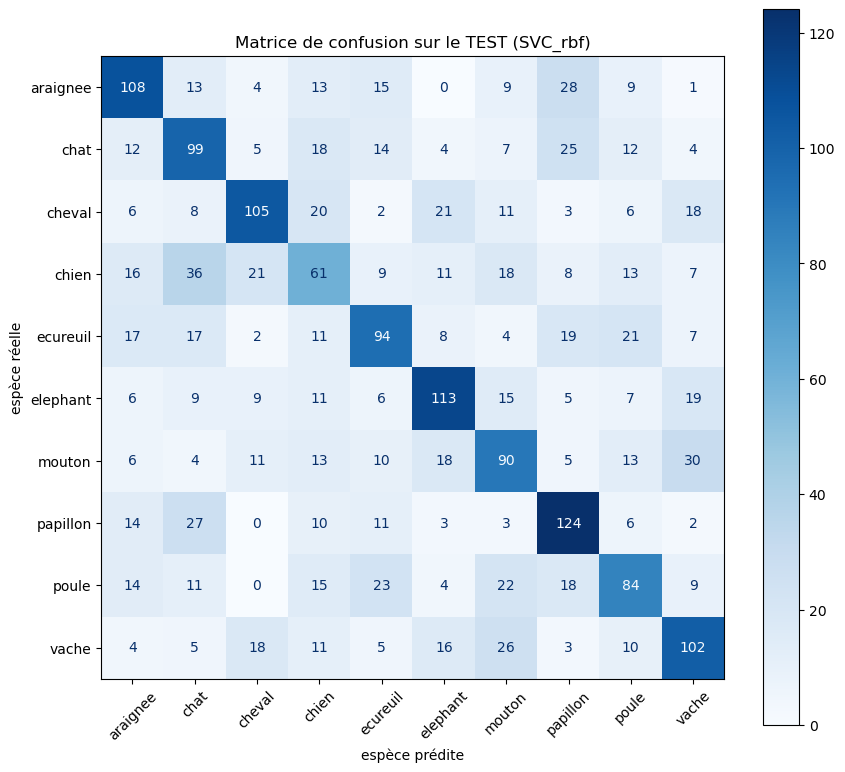

accuracy par classe sur le test :
  papillon   0.620
  elephant   0.565
  araignee   0.540
  cheval     0.525
  vache      0.510
  chat       0.495
  ecureuil   0.470
  mouton     0.450
  poule      0.420
  chien      0.305


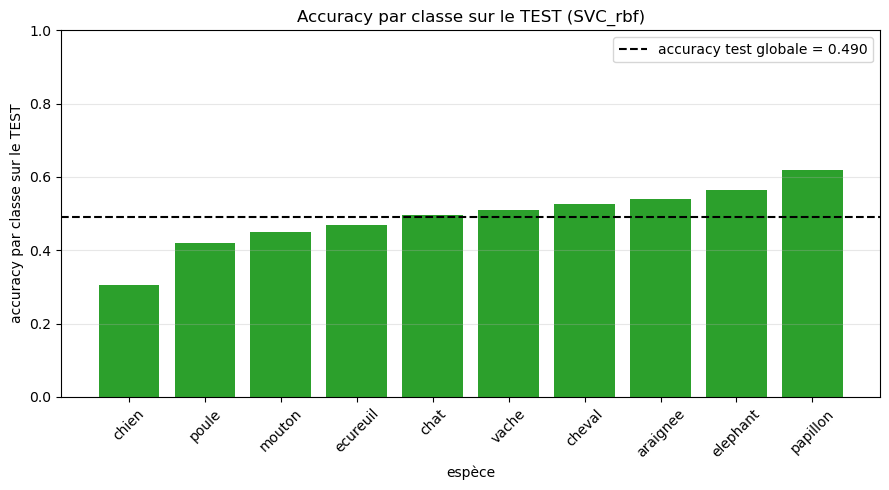

In [5]:
# matrice de confusion et accuracy par classe du champion, sur le test
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_estimator(champion[1], X_test, y_test, display_labels=classes, cmap="Blues", ax=ax, colorbar=True, xticks_rotation=45)
ax.set_xlabel("espèce prédite")
ax.set_ylabel("espèce réelle")
ax.set_title(f"Matrice de confusion sur le TEST ({champion[0]})")
fig.tight_layout()
plt.show()

cm = confusion_matrix(y_test, champion[1].predict(X_test))
par_classe = np.diag(cm) / cm.sum(axis=1)
ordre = np.argsort(par_classe)
print("accuracy par classe sur le test :")
for idx in ordre[::-1]:
    print(f"  {classes[idx]:10s} {par_classe[idx]:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(np.array(classes)[ordre], par_classe[ordre], color="tab:green")
ax.axhline(champion[3], color="black", linestyle="--", label=f"accuracy test globale = {champion[3]:.3f}")
ax.set_xlabel("espèce")
ax.set_ylabel("accuracy par classe sur le TEST")
ax.set_title(f"Accuracy par classe sur le TEST ({champion[0]})")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## Discussion :

Classement : le SVC RBF est le meilleur des trois modèles en validation croisée comme en test (0.4900 d'accuracy test), devant la forêt aléatoire (0.4260) et la régression logistique (0.3915). C'est 4.9 fois la baseline du hasard (0.10), mais loin d'une reconnaissance fiable.

Lecture par classe : les espèces à silhouette ou palette distinctives résistent le mieux, papillon (0.62), éléphant (0.565) et araignée (0.54). La pire est chien (0.305), exactement l'effet attendu de la variance intra-classe, une classe qui regroupe des races très différentes ne présente aucun motif de couleur ou de contour stable. Les confusions dominantes de la matrice confirment cette lecture : chien pris pour chat (36 cas sur 200), vache et mouton confondus entre eux (26 et 30 cas selon le sens, animaux de prairie sur fonds similaires), poule prise pour écureuil (23 cas, tons bruns proches).

Surapprentissage : le SVC et la forêt atteignent 1.0000 d'accuracy train pour respectivement 0.4631 et 0.4161 de CV. Les modèles mémorisent des configurations de descripteurs qui ne généralisent qu'à moitié, signe que la représentation ne porte qu'une partie du signal. Couleur et contours globaux ne suffisent pas à caractériser une espèce, le facteur limitant est la représentation, pas le classifieur.

## Conclusion :

Sur 10 000 photos d'animaux réparties en dix classes équilibrées, un SVC RBF réglé par validation croisée sur des descripteurs classiques (histogramme de couleur et HOG) atteint 0.4900 d'accuracy test, 4.9 fois le hasard, avec un fort surapprentissage (train 1.0000, CV 0.4631). L'analyse par classe et la matrice de confusion montrent que les erreurs suivent la logique des descripteurs, palettes et silhouettes proches se confondent, et que la variance intra-classe (races multiples, fonds variés) plafonne cette approche. Le prolongement naturel serait de remplacer les descripteurs artisanaux par des embeddings d'un réseau pré-entraîné gelé, à classifieurs identiques, ce que l'exercice 7 éclaire sous l'angle non supervisé : la limite vient bien de la représentation.